# Cairo Metro stations within 5 km of Sadat

**Question:** which Cairo Metro stations lie within 5 km of Sadat (Tahrir), the central interchange, and how far is each one?

Data: Cairo Metro station nodes from OpenStreetMap, (c) OpenStreetMap contributors, ODbL (see `showcase/README.md`). Run from the repository root.

## 1. Load the data
The CSV has `latitude` and `longitude` columns in WGS 84 degrees.

In [1]:
import sys
from pathlib import Path
# works from the repository root and from showcase/ (as nbconvert runs it)
ROOT = Path.cwd() if (Path.cwd() / 'showcase').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'showcase'))
import make_showcase as ms
from csv_to_geojson import convert_file

path = str(ROOT / 'showcase' / 'data' / 'cairo_metro_stations.csv')
print(open(path, encoding='utf-8').read().splitlines()[:3])

['osm_id,name,name_ar,latitude,longitude', '312555676,Maadi,المعادى,29.9598395,31.2580736', '316631605,Omm El Misryeen,أم المصريين,30.0052084,31.2079638']


## 2. Convert with csv_to_geojson
`convert_file` detects the columns and reports rows it could not parse.

In [2]:
result = convert_file(path)
print(result.lat_column, result.lon_column)
print(len(result.geojson['features']), 'features,', len(result.errors), 'rows skipped')
print(result.geojson['features'][0]['geometry'])  # [lon, lat]

latitude longitude
86 features, 0 rows skipped
{'type': 'Point', 'coordinates': [31.2580736, 29.9598395]}


## 3. Add geodesic distances to Sadat
Great-circle distance in km (haversine, WGS 84 mean radius), not planar maths on degrees.

In [3]:
gj, summary, _ = ms.analyse(path)
summary

{'stations': 86,
 'within_5km': 32,
 'within_2km': 8,
 'median_km': 6.78,
 'nearest': 'Saad Zaghloul',
 'nearest_km': 0.861,
 'farthest': 'Helwan',
 'farthest_km': 23.688,
 'lat_column': 'latitude',
 'lon_column': 'longitude'}

## 4. Inspect the nearest and farthest stations

In [4]:
stations = [f['properties'] for f in gj['features'] if f['properties']['feature_type'] == 'station']
def show(rows):
    print(f"{'name':28} {'km':>7}  band")
    for p in rows:
        print(f"{p['name'][:28]:28} {p['dist_to_sadat_km']:7.2f}  {p['band']}")
show(stations[:8])
print('...')
show(stations[-3:])

name                              km  band
Sadat                           0.00  0-2 km
Saad Zaghloul                   0.86  0-2 km
Mohamed Naguib                  0.87  0-2 km
Opera                           1.02  0-2 km
Nasser                          1.12  0-2 km
Masbero                         1.32  0-2 km
Attaba                          1.46  0-2 km
Sayyeda Zeinab                  1.64  0-2 km
...
name                              km  band
Adly Mansour                   21.26  over 10 km
Ain Helwan                     21.93  over 10 km
Helwan                         23.69  over 10 km


## 5. Map

mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-8q4lec5z because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


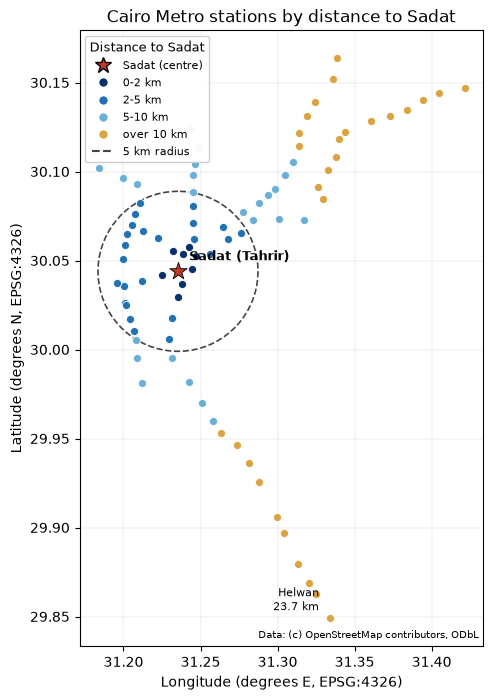

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 8))
ms.plot_map(ax, gj)
ax.set_title('Cairo Metro stations by distance to Sadat')
ax.text(0.99, 0.01, ms.CREDIT, transform=ax.transAxes, ha='right', va='bottom', fontsize=7)
plt.show()

The same steps, plus `map.geojson`, `map.png` and the Leaflet page, are written by `python showcase/make_showcase.py`.